In [1]:
import pandas as pd
import numpy as np
from catboost import CatBoostRegressor
from catboost.utils import get_gpu_device_count
import optuna
import sys
from pathlib import Path
import warnings

DIR_ROOT = Path.cwd().parent.parent.parent
sys.path.insert(0, str(DIR_ROOT))

warnings.filterwarnings("ignore")

%load_ext autoreload
%autoreload 2

/home/koyo-ai/miniconda3/envs/homeless/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SEED = 987
TRACK = "list_aware"                     # "off_market" or "list_aware"
VAL_START = pd.Timestamp("2025-12-01")    # sales on or after this date are validation
N_TRIALS = 100                             # optuna trials
EARLY_STOPPING_ROUNDS = 100               # only used when ES_FRACTION > 0
ES_FRACTION = 0.0                         # latest share of each fold's training rows used for early stopping
K_FOLDS = 5                              # CV validates on each of the last K_FOLDS months before VAL_START
META_MONTHS = 6                          # out-of-fold predictions for the meta model also cover the last META_MONTHS months before VAL_START
MODEL_NAME = "catboost"                  # file name in oof_preds/<TRACK>/, change it for each model you want in the ensemble
DEBUG = True                             # print MdAPE and MAPE for every fold
TASK_TYPE = "GPU" if get_gpu_device_count() > 0 else "CPU"
print("CatBoost task type:", TASK_TYPE)

CatBoost task type: GPU


In [3]:
import data

listings = data.load("listings")
off_market = data.load("off_market")
list_aware = data.load("list_aware")

In [ ]:
from xxbonkxx_features import off_market_features, list_aware_features

base_features = off_market_features if TRACK == "off_market" else list_aware_features

CATEGORICAL_FEATURES = [
    "community",
    "house_type",
    "house_style",
    "is_apartment",
]

def make_features(homes, **kwargs):
    """base_features with the categorical columns as strings, which CatBoost needs:
    it rejects NaN in categorical features, so missing values become "missing"."""
    X = base_features(homes, **kwargs)
    for col in CATEGORICAL_FEATURES:
        X[col] = X[col].astype("object").fillna("missing").astype(str)
    return X

train = listings[listings["date_sold"] < VAL_START]
val = listings[listings["date_sold"] >= VAL_START]

y_train = np.log(train["sold_price"])
y_val = np.log(val["sold_price"])

print(f"Features: {make_features(train.iloc[:10]).columns.tolist()}")
print(f"train: {len(train):,} sales up to {VAL_START.date()}")
print(f"val:   {len(val):,} sales from {VAL_START.date()}")

Features: ['square_feet', 'bedrooms', 'washrooms', 'parking', 'lot_front', 'lot_depth', 'latitude', 'longitude', 'community', 'house_type', 'house_style', 'month', 'year', 'day', 'is_apartment', 'is_apartment_x_square_feet_0', 'is_apartment_x_square_feet_1', 'is_apartment_x_bedrooms_0', 'is_apartment_x_bedrooms_1', 'is_apartment_x_washrooms_0', 'is_apartment_x_washrooms_1', 'is_apartment_x_parking_0', 'is_apartment_x_parking_1', 'square_feet_x_bedrooms', 'square_feet_x_washrooms', 'square_feet_x_parking', 'bedrooms_x_washrooms', 'bedrooms_x_parking', 'washrooms_x_parking', 'month_sin', 'month_cos', 'lag_annual', 'lag_semi_annual', 'building_sales', 'building_log_ppsf', 'building_log_price', 'building_last_log_ppsf', 'building_days_since_sale', 'repeat_log_price', 'repeat_days_since_sale', 'remarks_renovated', 'remarks_updated', 'remarks_turnkey', 'remarks_kitchen', 'remarks_premium_kitchen', 'remarks_wood_floor', 'remarks_clean', 'remarks_needs_work', 'remarks_dated', 'remarks_split_be

In [5]:
def mdape_log(y_log, pred_log):
    return 100 * np.median(np.abs(np.exp(pred_log) / np.exp(y_log) - 1))

def mape_log(y_log, pred_log):
    return 100 * np.mean(np.abs(np.exp(pred_log) / np.exp(y_log) - 1))

def mdape(y, pred):
    return 100 * np.median(np.abs(pred - y) / np.abs(y))

def mape(y, pred):
    return 100 * np.mean(np.abs(pred - y) / np.abs(y))

target_space = "log"

In [6]:
from training_utils import walk_forward_folds

BASE_PARAMS = {
    "loss_function": "RMSE",
    "eval_metric": "MAE",
    "bootstrap_type": "Bernoulli",  # lets subsample work on both CPU and GPU
    "task_type": TASK_TYPE,
    "random_seed": SEED,
    "verbose": 0,
    "allow_writing_files": False,
}


def make_model(params):
    return CatBoostRegressor(**BASE_PARAMS, **params, cat_features=CATEGORICAL_FEATURES)


def cv_months(K, end=VAL_START):
    """The K calendar months just before `end`, oldest first."""
    return pd.period_range(end=(end - pd.Timedelta(days=1)).to_period("M"), periods=K, freq="M")


def cross_val(folds, y, params, debug=False, target_space="log"):
    """Monthly walk-forward CV, the way `python run.py validate` works: each fold
    predicts one month's sales (answers hidden) with a model trained on every earlier sale.
    `folds` comes from walk_forward_folds, so features are built once, not per trial.
    `y` is indexed like the homes the folds were built from. Early stopping uses the
    latest ES_FRACTION of each fold's training rows, never the validated month.
    Returns (mean validation loss, mean boosting rounds used) over the folds."""
    mdape_scores = []
    mape_scores = []
    rounds = []
    for fold in folds:
        X_tr, X_va = fold.X_train, fold.X_homes
        n_fit = int(len(X_tr) * (1 - ES_FRACTION))
        X_fit, X_es = X_tr.iloc[:n_fit], X_tr.iloc[n_fit:]
        y_fit, y_es, y_va = y.loc[X_fit.index], y.loc[X_es.index], y.loc[X_va.index]

        model = make_model(params)
        if len(X_es):
            model.fit(X_fit, y_fit, eval_set=(X_es, y_es),
                      early_stopping_rounds=EARLY_STOPPING_ROUNDS, use_best_model=True)
        else:
            model.fit(X_fit, y_fit)
        rounds.append(model.tree_count_)
        pred = model.predict(X_va)
        if target_space == "log":
            mdape_scores.append(mdape_log(y_va, pred))
            mape_scores.append(mape_log(y_va, pred))
        else:
            mdape_scores.append(mdape(y_va, pred))
            mape_scores.append(mape(y_va, pred))

        if debug:
            print(f"{fold.month}: train {len(X_fit):,}  early stop {len(X_es):,}  val {len(X_va):,}  "
                  f"rounds {rounds[-1]}  MdAPE {mdape_scores[-1]:.2f}%  MAPE {mape_scores[-1]:.2f}%", flush=True)

    print(f"mean MdAPE {np.mean(mdape_scores):.2f}%  mean MAPE {np.mean(mape_scores):.2f}%", flush=True)
    return np.mean(mdape_scores), int(np.mean(rounds))

In [ ]:
cv_folds = walk_forward_folds(train, make_features, TRACK, months=cv_months(K_FOLDS))
print("CV months:", ", ".join(str(fold.month) for fold in cv_folds))

def objective(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, step=0.01),
        "depth": trial.suggest_int("depth", 4, 10),
        "iterations": trial.suggest_int("iterations", 200, 2000, step=200),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1e-3, 10.0, log=True),
        "random_strength": trial.suggest_float("random_strength", 1e-3, 10.0, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0, step=0.1),
        "border_count": trial.suggest_categorical("border_count", [64, 128, 254]),
        "one_hot_max_size": trial.suggest_int("one_hot_max_size", 2, 10),
    }
    score, n_rounds = cross_val(cv_folds, y_train, params, debug=DEBUG, target_space=target_space)
    trial.set_user_attr("n_rounds", n_rounds)
    return score

CV months: 2025-07, 2025-08, 2025-09, 2025-10, 2025-11


In [8]:
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED), study_name="catboost")
study.optimize(objective, n_trials=N_TRIALS)

print("best CV MdAPE:", round(study.best_value, 2))
print("best params:", study.best_params)
print("boosting rounds:", study.best_trial.user_attrs["n_rounds"])

[I 2026-11-05 20:04:51,288] A new study created in memory with name: catboost
Default metric period is 5 because MAE is/are not implemented for GPU


2025-07: train 130,045  early stop 0  val 2,068  rounds 1800  MdAPE 4.10%  MAPE 5.34%


Default metric period is 5 because MAE is/are not implemented for GPU


2025-08: train 132,113  early stop 0  val 1,666  rounds 1800  MdAPE 4.00%  MAPE 5.18%


Default metric period is 5 because MAE is/are not implemented for GPU


2025-09: train 133,779  early stop 0  val 2,035  rounds 1800  MdAPE 4.05%  MAPE 5.21%


... (992 outputs left out)

Default metric period is 5 because MAE is/are not implemented for GPU


2025-11: train 138,064  early stop 0  val 1,867  rounds 2000  MdAPE 4.03%  MAPE 5.17%
mean MdAPE 3.96%  mean MAPE 5.09%


[I 2026-11-05 23:39:01,619] Trial 99 finished with value: 3.960545636150518 and parameters: {'learning_rate': 0.05, 'depth': 10, 'iterations': 2000, 'l2_leaf_reg': 4.223599226697928, 'random_strength': 7.450184127824552, 'subsample': 0.9, 'border_count': 254, 'one_hot_max_size': 9}. Best is trial 77 with value: 3.934018190921369.


best CV MdAPE: 3.93
best params: {'learning_rate': 0.05, 'depth': 10, 'iterations': 2000, 'l2_leaf_reg': 4.809832193856093, 'random_strength': 3.0009335320617767, 'subsample': 0.9, 'border_count': 254, 'one_hot_max_size': 9}
boosting rounds: 2000


In [15]:
study.best_params

{'learning_rate': 0.05,
 'depth': 10,
 'iterations': 2000,
 'l2_leaf_reg': 4.809832193856093,
 'random_strength': 3.0009335320617767,
 'subsample': 0.9,
 'border_count': 254,
 'one_hot_max_size': 9}

In [9]:
from optuna.importance import get_param_importances

importance = get_param_importances(study)

for param, score in importance.items():
    print(f"{param}: {score:.4f}")

subsample: 0.2081
one_hot_max_size: 0.1911
random_strength: 0.1520
learning_rate: 0.1417
iterations: 0.1296
l2_leaf_reg: 0.0952
depth: 0.0679
border_count: 0.0145


In [10]:
from training_utils import walk_forward_folds, walk_forward_validate

def fit_model(X_train, y_train):
    return make_model(study.best_params).fit(X_train, y_train)


folds = walk_forward_folds(listings, make_features, TRACK)
validation = walk_forward_validate(listings, make_features, fit_model, TRACK, folds=folds)
model, X_train, X_val = validation.model, validation.X_train, validation.X_val
actual, predicted = validation.actual, validation.predicted

print("Columns in X_train:")
print(X_train.columns)
print("\n")
feature_importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
most_important_features = feature_importances.head(20)
least_important_features = feature_importances.tail(20)
print("Most Important Features:")
print(most_important_features)
print("\n")
print("Least Important Features:")
print(least_important_features)

Default metric period is 5 because MAE is/are not implemented for GPU


2025-12: trained on 139,931 earlier sales, predicted 1,238 homes  MdAPE 3.80%  MAPE 4.87%


Default metric period is 5 because MAE is/are not implemented for GPU


2026-01: trained on 141,169 earlier sales, predicted 1,058 homes  MdAPE 3.87%  MAPE 4.90%


Default metric period is 5 because MAE is/are not implemented for GPU


2026-02: trained on 142,227 earlier sales, predicted 1,442 homes  MdAPE 4.00%  MAPE 5.18%


... (2 outputs left out)

Default metric period is 5 because MAE is/are not implemented for GPU


2026-04: trained on 145,485 earlier sales, predicted 2,224 homes  MdAPE 4.03%  MAPE 5.14%


Default metric period is 5 because MAE is/are not implemented for GPU


2026-05: trained on 147,709 earlier sales, predicted 2,291 homes  MdAPE 4.33%  MAPE 5.40%
list_aware  MdAPE 4.04%  MAPE 5.17%
Columns in X_train:
Index(['square_feet', 'bedrooms', 'washrooms', 'parking', 'lot_front',
       'lot_depth', 'latitude', 'longitude', 'community', 'house_type',
       'house_style', 'month', 'year', 'day', 'is_apartment',
       'is_apartment_x_square_feet_0', 'is_apartment_x_square_feet_1',
       'is_apartment_x_bedrooms_0', 'is_apartment_x_bedrooms_1',
       'is_apartment_x_washrooms_0', 'is_apartment_x_washrooms_1',
       'is_apartment_x_parking_0', 'is_apartment_x_parking_1',
       'square_feet_x_bedrooms', 'square_feet_x_washrooms',
       'square_feet_x_parking', 'bedrooms_x_washrooms', 'bedrooms_x_parking',
       'washrooms_x_parking', 'month_sin', 'month_cos', 'lag_annual',
       'lag_semi_annual', 'building_sales', 'building_log_ppsf',
       'building_log_price', 'building_last_log_ppsf',
       'building_days_since_sale', 'repeat_log_price',


In [ ]:
from training_utils import save_oof_predictions

meta_folds = walk_forward_folds(listings, make_features, TRACK, months=cv_months(META_MONTHS))
print("Meta model training months:", ", ".join(str(fold.month) for fold in meta_folds))
meta_validation = walk_forward_validate(listings, make_features, fit_model, TRACK, folds=meta_folds)
save_oof_predictions(MODEL_NAME, meta_validation, validation)

Meta model training months: 2025-06, 2025-07, 2025-08, 2025-09, 2025-10, 2025-11


Default metric period is 5 because MAE is/are not implemented for GPU


2025-06: trained on 127,762 earlier sales, predicted 2,283 homes  MdAPE 4.24%  MAPE 5.45%


Default metric period is 5 because MAE is/are not implemented for GPU


2025-07: trained on 130,045 earlier sales, predicted 2,068 homes  MdAPE 3.91%  MAPE 5.21%


Default metric period is 5 because MAE is/are not implemented for GPU


... (4 outputs left out)

2025-10: trained on 135,814 earlier sales, predicted 2,250 homes  MdAPE 3.81%  MAPE 4.86%


Default metric period is 5 because MAE is/are not implemented for GPU


2025-11: trained on 138,064 earlier sales, predicted 1,867 homes  MdAPE 4.02%  MAPE 5.22%
list_aware  MdAPE 3.99%  MAPE 5.15%
Saved 22,238 out-of-fold predictions (2025-06 to 2026-05) to /home/koyo-ai/ssd2/private/SSU-Data-Dash/notebooks/xxbonkxx/models/oof_preds/list_aware/catboost.parquet


PosixPath('/home/koyo-ai/ssd2/private/SSU-Data-Dash/notebooks/xxbonkxx/models/oof_preds/list_aware/catboost.parquet')

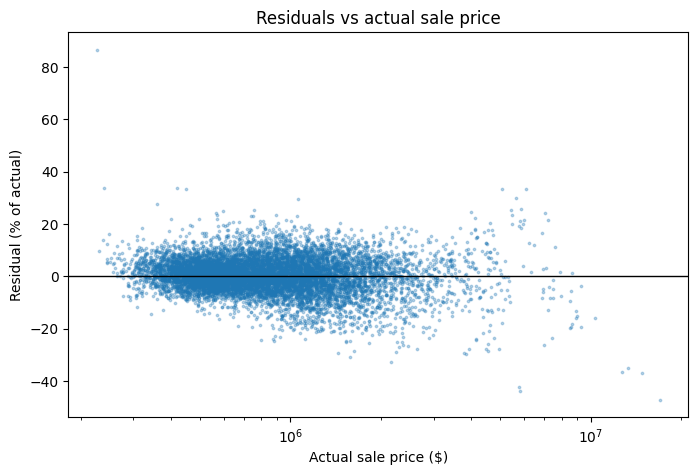

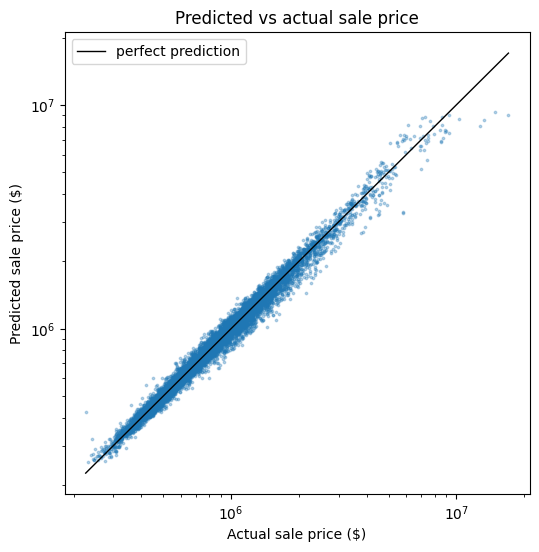

In [12]:
import diagnostics

diagnostics.plot_residuals_vs_actual(actual, predicted)
diagnostics.plot_predicted_vs_actual(actual, predicted)



In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_residuals_by_feature(X, actual, predicted, max_categories=20, n_cols=3):
    """One panel per column of X: a scatter plot for continuous columns and a box plot
    for categorical ones. Numeric columns with at most max_categories distinct values
    (bedrooms, month, ...) count as categorical. Columns with more categories than that
    show only their max_categories most common values."""
    residual = percent_error(actual, predicted)
    n_rows = int(np.ceil(len(X.columns) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows), squeeze=False)

    for ax, column in zip(axes.flat, X.columns):
        values = X[column].to_numpy()
        is_numeric = pd.api.types.is_numeric_dtype(X[column])
        if is_numeric and X[column].nunique() > max_categories:
            ax.scatter(values, residual, s=3, alpha=0.3)
        else:
            if is_numeric:
                order = sorted(X[column].value_counts().index[:max_categories])
            else:
                order = (
                    pd.DataFrame({"category": X[column], "residual": residual})
                    .groupby("category")["residual"]
                    .mean()
                    .sort_values(ascending=False)
                    .head(max_categories)
                    .index
                    .tolist()
                )
            sns.boxplot(x=values, y=residual, order=order, showfliers=False, ax=ax)
            ax.tick_params(axis="x", rotation=90)
        ax.axhline(0, color="black", linewidth=1)
        ax.set(title=column, xlabel="", ylabel="Residual (%)")

    for ax in axes.flat[len(X.columns):]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()

def percent_error(actual, predicted):
    return 100 * (np.asarray(predicted) / np.asarray(actual) - 1)

plot_residuals_by_feature(X_val, actual, predicted)

In [14]:
def evaluate_by_quantile(y_true, y_pred, n_bins=10):
    df = pd.DataFrame({
        "actual": y_true,
        "predicted": y_pred
    })
    df["quantile"] = pd.qcut(
        df["actual"], q=n_bins, duplicates="drop"
    )
    df["residual"] = df["actual"] - df["predicted"]
    df["residual_percent"] = 100 * np.abs(df["residual"]) / df["actual"]
    return df.groupby("quantile", observed=True).agg(
        count=("actual", "size"),
        MAE=("residual", lambda x: x.abs().mean()),
        mean_residual=("residual", "mean"),
        mean_residual_percent=("residual_percent", "mean"),
        mdape=("residual_percent", lambda x: np.median(np.abs(x))),
        mape=("residual_percent", lambda x: np.mean(np.abs(x)))
    )

evaluate_by_quantile(actual, predicted, n_bins=20)

,count,MAE,mean_residual,mean_residual_percent,mdape,mape
quantile,,,,,,
"(226199.999, 388140.0]",504,15227.136905,-8357.942460,4.568766,3.741785,4.568766
"(388140.0, 440480.0]",503,16848.564612,-7562.429423,4.042871,3.410144,4.042871
"(440480.0, 482100.0]",505,17530.758416,-4646.928713,3.793701,2.960069,3.793701
"(482100.0, 521000.0]",503,19800.457256,-4121.960239,3.950439,3.247978,3.950439
"(521000.0, 558000.0]",503,20691.970179,-3934.168986,3.838351,3.240599,3.838351
"(558000.0, 597040.0]",503,23945.638171,-5716.632207,4.145508,3.312250,4.145508
"(597040.0, 643360.0]",503,25022.109344,-5826.741551,4.037545,3.356862,4.037545
"(643360.0, 692020.0]",504,29949.928571,-6164.444444,4.496959,3.529747,4.496959
"(692020.0, 747620.0]",503,33273.330020,-6925.115308,4.613456,3.825725,4.613456
